# Адіабатичне наближення (Борна–Оппенгеймера): криві потенціальної енергії молекул (PySCF)

**Мета роботи:**

1. Побачити, що таке *електронний терм* $E_{el}(R)$ — енергія електронів при **закріплених** ядрах як функція геометрії.
2. Просканувати відстань між атомами в H$_2$ і LiH та побудувати криві потенціальної енергії.
3. Перевірити, чи виходить крива на **дисоціаційну межу** (суму енергій вільних атомів) для RHF, UHF і точного (FCI) розрахунків.
4. Із кривої отримати спектроскопічні константи ($R_e$, $D_e$, $\omega_e$) і переконатись, що поверхня **не залежить від мас ядер** (H$_2$ vs D$_2$).
5. Оцінити, **коли** адіабатичне наближення працює, а коли ні (уникнене перетинання термів у LiH).

In [ ]:
!pip install pyscf

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pyscf import gto, scf, fci

np.set_printoptions(precision=6, suppress=True)

HA2EV  = 27.211386      # Hartree -> eV
HA2CM  = 219474.63      # Hartree -> см^-1
AMU    = 1822.888486    # а.о.м. -> маса електрона
ANG    = 1.8897261      # Å -> bohr

## Частина 0. Ідея

Повний гамільтоніан молекули $\hat H=\hat T_N+\hat T_e+\hat V_{ee}+\hat V_{eN}+\hat V_{NN}$.
Через велику різницю мас ($m_e/M\sim10^{-3}$–$10^{-4}$) електрони «встигають» підлаштуватися під ядра, тому

$$\Psi(\mathbf r,\mathbf R)\approx\chi(\mathbf R)\,\psi_{\mathbf R}(\mathbf r),\qquad
\big[\hat T_e+\hat V_{ee}+\hat V_{eN}\big]\psi_{\mathbf R}=E_{el}(\mathbf R)\,\psi_{\mathbf R}$$

Ядра рухаються в потенціалі $U(\mathbf R)=E_{el}(\mathbf R)+V_{NN}(\mathbf R)$ — це і є **поверхня потенціальної енергії**.
Для двоатомної молекули це проста крива $U(R)$. Саме її рахує будь-яка програма квантової хімії: `mf.e_tot` при заданій геометрії **вже включає** $V_{NN}$.

Нижче `E_scan` — функція, що рахує $U(R)$ для заданого методу.

In [ ]:
def make_mol(atom, basis, R, spin=0):
    return gto.M(atom=atom.format(R=R), basis=basis, spin=spin, unit='Angstrom', verbose=0)

def energy(atom, basis, R, method):
    mol = make_mol(atom, basis, R)
    if method == 'RHF':
        return scf.RHF(mol).run().e_tot
    if method == 'UHF':                      # дозволяємо порушення спінової симетрії
        mf = scf.UHF(mol).run()
        mo = mf.stability()[0]               # перевірка стійкості -> шукаємо нижчий розв'язок
        mf.kernel(mf.make_rdm1(mo, mf.mo_occ))
        return mf.e_tot
    if method == 'FCI':                      # точний розв'язок у даному базисі
        mf = scf.RHF(mol).run()
        return fci.FCI(mf).kernel()[0]

def scan(atom, basis, Rs, method):
    return np.array([energy(atom, basis, R, method) for R in Rs])

def atom_energy(sym, basis, spin, method):
    mol = gto.M(atom=sym, basis=basis, spin=spin, verbose=0)
    if method == 'FCI':
        return fci.FCI(scf.ROHF(mol).run()).kernel()[0]
    return scf.UHF(mol).run().e_tot

## Частина 1. Молекула H$_2$: скан відстані, RHF vs UHF vs FCI

Беремо базис `cc-pVDZ`. Дисоціаційна межа — це **два атоми H** на нескінченній відстані: $U(\infty)=2E(\mathrm H)$.
Енергію атома рахуємо в **тому самому** базисі (інакше порівняння некоректне).

In [17]:
atom_H2, basis = 'H 0 0 0; H 0 0 {R}', 'cc-pvdz'
Rs = np.concatenate([np.arange(0.4, 2.0, 0.1), np.arange(2.0, 6.01, 0.5)])

E_rhf = scan(atom_H2, basis, Rs, 'RHF')
E_uhf = scan(atom_H2, basis, Rs, 'UHF')
E_fci = scan(atom_H2, basis, Rs, 'FCI')

E_H   = atom_energy('H', basis, 1, 'UHF')
E_lim = 2*E_H
print(f'E(H) = {E_H:.6f} Ha,   межа дисоціації 2E(H) = {E_lim:.6f} Ha')
print(f'Мінімум FCI: R = {Rs[E_fci.argmin()]:.2f} Å,  U = {E_fci.min():.6f} Ha')

E(H) = -0.499278 Ha,   межа дисоціації 2E(H) = -0.998557 Ha
Мінімум FCI: R = 0.80 Å,  U = -1.162751 Ha


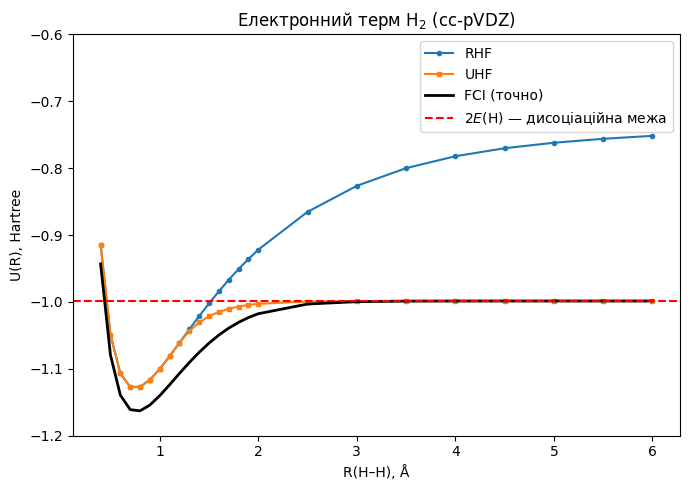

R=0.70 Å:  U-2E(H):  RHF -0.1284   UHF -0.1284   FCI -0.1623  Ha
R=2.00 Å:  U-2E(H):  RHF +0.0766   UHF -0.0042   FCI -0.0190  Ha
R=4.00 Å:  U-2E(H):  RHF +0.2164   UHF -0.0000   FCI -0.0000  Ha
R=6.00 Å:  U-2E(H):  RHF +0.2468   UHF -0.0000   FCI -0.0000  Ha


In [ ]:
plt.figure(figsize=(7,5))
plt.plot(Rs, E_rhf, 'o-', ms=3, label='RHF')
plt.plot(Rs, E_uhf, 's-', ms=3, label='UHF')
plt.plot(Rs, E_fci, 'k-', lw=2, label='FCI (точно)')
plt.axhline(E_lim, color='r', ls='--', label=r'$2E(\mathrm{H})$ — дисоціаційна межа')
plt.xlabel('R(H–H), Å'); plt.ylabel('U(R), Hartree')
plt.ylim(-1.2, -0.6); plt.title('Електронний терм H$_2$ (cc-pVDZ)')
plt.legend(); plt.tight_layout(); plt.show()

for R in [0.74, 2.0, 4.0, 6.0]:
    i = np.argmin(abs(Rs-R))
    print(f'R={Rs[i]:.2f} Å:  U-2E(H):  RHF {E_rhf[i]-E_lim:+.4f}   UHF {E_uhf[i]-E_lim:+.4f}   FCI {E_fci[i]-E_lim:+.4f}  Ha')

**Що ми бачимо.**

* **FCI** виходить рівно на $2E(\mathrm H)$ — правильна дисоціація.
* **RHF** при великих $R$ **не** виходить на межу: єдина просторова орбіталь $\sigma_g^2$ описує $50\%$ іонних структур ($\mathrm H^+\mathrm H^-$), які при $R\to\infty$ мають значно вищу енергію. Це не помилка адіабатичного наближення, а недолік *одновизначникового* наближення для електронної задачі.
* **UHF** виходить на межу, але ціною порушення спінової симетрії. Енергія правильна, хвильова функція — суміш синглету й триплету.

> **Завдання:** обчисліть $\langle S^2\rangle$ для UHF при $R=0.74$ та $R=4$ Å (`mf.spin_square()`).

In [ ]:
# Ваш код тут

## Частина 2. Спектроскопічні константи з кривої $U(R)$

Адіабатичне наближення означає, що ядра рухаються **в потенціалі $U(R)$**. Біля мінімуму розкладаємо у ряд:
$U(R)\approx U(R_e)+\tfrac12 k (R-R_e)^2$, де $k=U''(R_e)$, і гармонічна частота

$$\omega_e=\sqrt{k/\mu},\qquad \mu=\frac{M_1M_2}{M_1+M_2},\qquad D_e=2E(\mathrm{H})-U(R_e).$$

Для аналізу беремо густішу сітку біля мінімуму й підганяємо поліном.

In [18]:
def constants(atom, basis, R0, R1, n, E_atoms, masses, method='FCI', deg=6):
    Rg = np.linspace(R0, R1, n)
    Eg = scan(atom, basis, Rg, method)
    Rb = Rg*ANG                                    # у борах
    i0 = Eg.argmin(); m = slice(max(i0-5,0), i0+6) # локальна ділянка навколо мінімуму
    p  = np.polyfit(Rb[m], Eg[m], deg)
    Re = Rb[m][np.argmin(np.polyval(p, Rb[m]))]
    from scipy.optimize import minimize_scalar
    Re = minimize_scalar(lambda x: np.polyval(p, x), bracket=(Rb[i0-1], Rb[i0], Rb[i0+1])).x
    k  = np.polyval(np.polyder(p, 2), Re)          # Ha/bohr^2
    out = {}
    for name, (m1, m2) in masses.items():
        mu = m1*m2/(m1+m2)*AMU
        out[name] = np.sqrt(k/mu)*HA2CM
    De = (E_atoms - np.polyval(p, Re))*HA2EV
    return Re/ANG, De, k, out

masses_H2 = {'H2': (1.00783, 1.00783), 'HD': (1.00783, 2.01410), 'D2': (2.01410, 2.01410)}
Re, De, k, w = constants(atom_H2, basis, 0.55, 1.05, 26, E_lim, masses_H2)
print(f'H2 (FCI/cc-pVDZ):  Re = {Re:.3f} Å (експ. 0.741),  De = {De:.2f} еВ (експ. 4.75),  k = {k:.3f} Ha/bohr²')
for n_, v in w.items(): print(f'   ω_e({n_}) = {v:7.0f} см⁻¹')
print('   експеримент ω_e(H2) = 4401 см⁻¹ ;  ω(H2)/ω(D2) =', round(w['H2']/w['D2'],3), ' (√2 = 1.414)')

H2 (FCI/cc-pVDZ):  Re = 0.761 Å (експ. 0.741),  De = 4.49 еВ (експ. 4.75),  k = 0.366 Ha/bohr²
   ω_e(H2) =    4382 см⁻¹
   ω_e(HD) =    3796 см⁻¹
   ω_e(D2) =    3100 см⁻¹
   експеримент ω_e(H2) = 4401 см⁻¹ ;  ω(H2)/ω(D2) = 1.414  (√2 = 1.414)


**Ключовий висновок.** Одна й та сама крива $U(R)$ (однакові $R_e$, $D_e$, $k$) дає різні частоти для H$_2$, HD, D$_2$ — відмінність лише через зведену масу $\mu$. Це і є зміст наближення: **електронна поверхня не залежить від мас ядер**, масам місце лише в ядерній задачі.

## Частина 3. Гідрид літію LiH

Тут 4 електрони; беремо базис `6-31G` і точний FCI. Дисоціаційна межа: $E(\mathrm{Li})+E(\mathrm H)$ (обидва — в тому самому базисі).

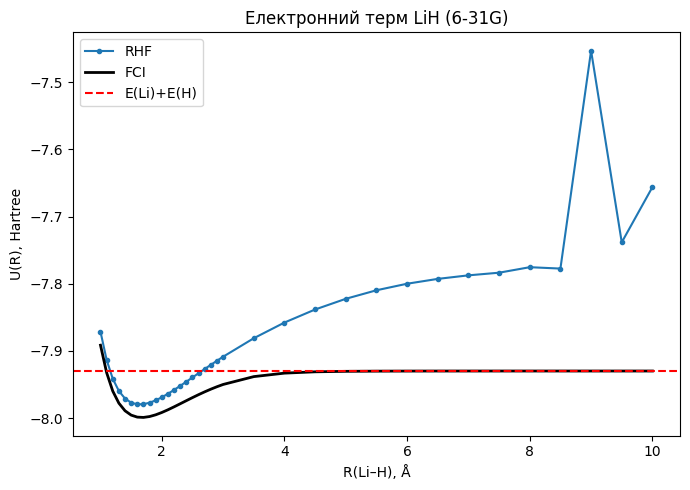

E(Li)+E(H) = -7.929787 Ha;   FCI(R=10 Å) − межа = -0.00 mHa;   RHF(R=10 Å) − межа = 273.5 mHa


In [ ]:
atom_LiH, basis2 = 'Li 0 0 0; H 0 0 {R}', '6-31g'
R_li = np.concatenate([np.arange(1.0, 3.0, 0.1), np.arange(3.0, 10.1, 0.5)])

E_li_rhf = scan(atom_LiH, basis2, R_li, 'RHF')
E_li_fci = scan(atom_LiH, basis2, R_li, 'FCI')
E_lim_li = atom_energy('Li', basis2, 1, 'FCI') + atom_energy('H', basis2, 1, 'FCI')

plt.figure(figsize=(7,5))
plt.plot(R_li, E_li_rhf, 'o-', ms=3, label='RHF')
plt.plot(R_li, E_li_fci, 'k-', lw=2, label='FCI')
plt.axhline(E_lim_li, color='r', ls='--', label='E(Li)+E(H)')
plt.xlabel('R(Li–H), Å'); plt.ylabel('U(R), Hartree'); plt.title('Електронний терм LiH (6-31G)')
plt.legend(); plt.tight_layout(); plt.show()
print(f'E(Li)+E(H) = {E_lim_li:.6f} Ha;   FCI(R=10 Å) − межа = {(E_li_fci[-1]-E_lim_li)*1000:.2f} mHa;   RHF(R=10 Å) − межа = {(E_li_rhf[-1]-E_lim_li)*1000:.1f} mHa')

In [ ]:
m_LiH = {'7LiH': (7.01600, 1.00783), '7LiD': (7.01600, 2.01410)}
Re, De, k, w = constants(atom_LiH, basis2, 1.35, 1.85, 26, E_lim_li, m_LiH)
print(f'LiH (FCI/6-31G):  Re = {Re:.3f} Å (експ. 1.595),  De = {De:.2f} еВ (експ. 2.52),  k = {k:.3f} Ha/bohr²')
for n_, v in w.items(): print(f'   ω_e({n_}) = {v:6.0f} см⁻¹')
print('   експеримент ω_e(LiH) = 1406 см⁻¹')

LiH (FCI/6-31G):  Re = 1.672 Å (експ. 1.595),  De = 1.88 еВ (експ. 2.52),  k = 0.055 Ha/bohr²
   ω_e(7LiH) =   1280 см⁻¹
   ω_e(7LiD) =    961 см⁻¹
   експеримент ω_e(LiH) = 1406 см⁻¹


**Зауваження.** Малий базис не дає кількісної згоди (це окремий пункт для самостійного вивчення), але якісно крива правильна: мінімум, обмежена яма і вихід на межу $\mathrm{Li}+\mathrm H$.
RHF для LiH на великих $R$ знову лежить вище межі — той самий дефект, що й для H$_2$.

## Частина 4. Коли адіабатичне наближення працює?

Критерій: відстань між електронними термами має бути **набагато більшою** за ядерні кванти $\hbar\omega$ (тоді неадіабатичний зв'язок $\sim \langle\psi_0|\nabla_R\psi_1\rangle\ \!/(E_1-E_0)$ малий).
Перевіримо для H$_2$ та LiH: порахуємо два нижчі синглетні $\Sigma^+$-терми методом FCI.

In [19]:
def two_roots(atom, basis, Rs, sym=False):
    res = []
    for R in Rs:
        mol = gto.M(atom=atom.format(R=R), basis=basis, unit='Angstrom', symmetry=sym, verbose=0)
        mf = scf.RHF(mol).run()
        cs = fci.FCI(mf); cs.nroots = 2
        fci.addons.fix_spin_(cs, shift=0.5, ss=0)      # лише синглети
        if sym: cs.wfnsym = 'A1'
        res.append(cs.kernel()[0])
    return np.array(res)

e = two_roots(atom_H2, basis, [0.74])[0]
gap = (e[1]-e[0])*HA2EV
hw = 4401/8065.54
print(f'H2, R=0.74 Å: E1−E0 = {gap:.2f} еВ;  ħω_e(H2) ≈ {hw:.3f} еВ;  відношення ≈ {gap/hw:.0f}')
print(f'm_e/m_p = {1/AMU:.2e},  (m_e/M)^(1/4) ≈ {AMU**-0.25:.2f} — малий параметр розкладу')

H2, R=0.74 Å: E1−E0 = 13.92 еВ;  ħω_e(H2) ≈ 0.546 еВ;  відношення ≈ 26
m_e/m_p = 5.49e-04,  (m_e/M)^(1/4) ≈ 0.15 — малий параметр розкладу


Для H$_2$ електронна щілина (14 еВ у малому базисі; експ. ≈12.7 еВ) у 25 разів більша за ядерний квант (0.55 еВ) — наближення чудове.

### Уникнене перетинання в LiH

У LiH дві діабатичні криві — **ковалентна** ($\mathrm{Li}+\mathrm H$) і **іонна** ($\mathrm{Li}^+ + \mathrm H^-$) — перетинаються на великих $R$. Оскільки обидві мають однакову симетрію ($^1\Sigma^+$), вони **не перетинаються, а відштовхуються** (правило заборони перетину). Біля цієї точки щілина мінімальна, і адіабатичне наближення стає ненадійним.

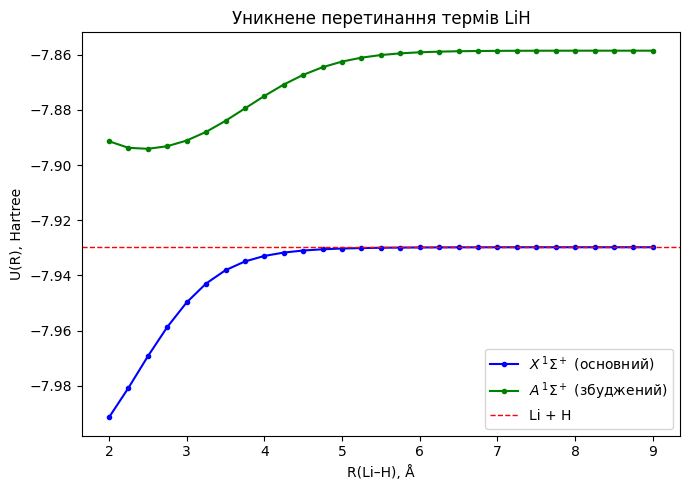

Мінімальна щілина 1.47 еВ при R ≈ 3.50 Å;  щілина при R_e: 2.72 еВ


In [20]:
R_ac = np.arange(2.0, 9.01, 0.25)
E2 = two_roots(atom_LiH, basis2, R_ac, sym=True)   # LiH: C∞v, лише A1 (Σ+)

plt.figure(figsize=(7,5))
plt.plot(R_ac, E2[:,0], 'b-o', ms=3, label=r'$X\,^1\Sigma^+$ (основний)')
plt.plot(R_ac, E2[:,1], 'g-o', ms=3, label=r'$A\,^1\Sigma^+$ (збуджений)')
plt.axhline(E_lim_li, color='r', ls='--', lw=1, label='Li + H')
plt.xlabel('R(Li–H), Å'); plt.ylabel('U(R), Hartree'); plt.legend()
plt.title('Уникнене перетинання термів LiH'); plt.tight_layout(); plt.show()

gap_ac = (E2[:,1]-E2[:,0])*HA2EV
i = gap_ac.argmin()
print(f'Мінімальна щілина {gap_ac[i]:.2f} еВ при R ≈ {R_ac[i]:.2f} Å;  щілина при R_e: {gap_ac[np.argmin(abs(R_ac-1.6))]:.2f} еВ')

У області мінімальної щілини змінюється характер основного стану (ковалентний $\leftrightarrow$ іонний), ядра «перестрибують» між термами — **неадіабатичні переходи** (формула Ландау–Зінера). Але біля $R_e$ щілина велика, і для коливальної спектроскопії LiH наближення Борна–Оппенгеймера працює добре.

## Частина 5. Завдання для самостійного виконання

1. **Базис.** Повторіть скан H$_2$ у `sto-3g`, `6-31g`, `cc-pvtz`. Як змінюються $R_e$, $D_e$, $\omega_e$? Який базис найближчий до експерименту?
2. **Інші молекули.** Просканйте HeH$^+$ (`charge=1`): на який *асимптотичний* продукт дисоціює (He + H$^+$ чи He$^+$ + H)? Чому? (Підказка: порівняйте потенціали іонізації He і H.)
3. **Ангармонізм.** Із поліноміальної підгонки знайдіть кубічну константу і оцініть $\omega_e x_e$. Порівняйте з експериментом для H$_2$ ($121$ см$^{-1}$).
4. **Сила в точці.** Обчисліть силу $F=-dU/dR$ чисельно і через `mf.nuc_grad_method().kernel()` (теорема Гельмана–Фейнмана). Де вона дорівнює нулю?
5. **Ізотопний ефект.** Нульова енергія $\tfrac12\hbar\omega$ у H$_2$ та D$_2$ дає різні $D_0=D_e-\tfrac12\hbar\omega$. Обчисліть різницю.

In [ ]:
# Тут і далі ваші розрахунки